# Per-class Calibration of Twi and Hausa Hate-Speech Classifiers
## Step 0 — Mandatory Pre-build Checks

**Three checks:**
1. Label strings — what does the loaded data actually call the classes?
2. Per-class test-set counts — is the rarest cell ≥ 30?
3. Schema parity — do both subsets expose the same fields?

In [24]:
# ── Dependencies ──────────────────────────────────────────────────────────────
import importlib, subprocess, sys

def ensure(package, import_name=None):
    name = import_name or package
    if importlib.util.find_spec(name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '-q'])

ensure('datasets')
ensure('huggingface_hub')
ensure('pandas')
ensure('scikit-learn', 'sklearn')
ensure('scipy')

import pandas as pd
from datasets import load_dataset
import huggingface_hub
print('datasets:', importlib.import_module('datasets').__version__)
print('huggingface_hub:', huggingface_hub.__version__)
print('pandas:', pd.__version__)

datasets: 5.0.1
huggingface_hub: 1.29.0
pandas: 3.0.5


### Authenticate with Hugging Face
The AfriHate dataset is gated.


In [25]:
from huggingface_hub import notebook_login
notebook_login()

### Load both subsets

In [26]:
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('Loading Twi subset...')
twi_ds = load_dataset('afrihate/afrihate', 'twi')
print('  done:', twi_ds)

print('\nLoading Hausa subset...')
hau_ds = load_dataset('afrihate/afrihate', 'hau')
print('  done:', hau_ds)

Loading Twi subset...
  done: DatasetDict({
    train: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 2564
    })
    validation: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 639
    })
    test: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 698
    })
})

Loading Hausa subset...
  done: DatasetDict({
    train: Dataset({
        features: ['id', 'tweet', 'label', 'length'],
        num_rows: 4566
    })
    validation: Dataset({
        features: ['id', 'tweet', 'label', 'length'],
        num_rows: 1029
    })
    test: Dataset({
        features: ['id', 'tweet', 'label', 'length'],
        num_rows: 1049
    })
})


---
## Check 1 — Label strings

In [28]:
twi_labels  = sorted(twi_ds['train'].unique('label'))
hau_labels  = sorted(hau_ds['train'].unique('label'))

print('CHECK 1: Label strings')
print(f'Twi  labels : {twi_labels}')
print(f'Hausa labels: {hau_labels}')

if twi_labels == hau_labels:
    print('\nBoth subsets share the same label strings.')
else:
    print('\nLabel strings differ between subsets — mappings must be applied per-language.')

# Store for downstream use — everything derives from this, never hardcoded
TWI_LABELS = twi_labels
HAU_LABELS = hau_labels

CHECK 1: Label strings
Twi  labels : ['Abuse', 'Hate', 'Normal']
Hausa labels: ['Abuse', 'Hate', 'Normal']

Both subsets share the same label strings.


---
## Check 2 — Per-class test-set counts
Does Twi's rarest test class have ≥ 30 instances?
If not, Hausa becomes the primary analysis and Twi is the imbalance-stress case.

In [31]:
MIN_CELL = 30  # threshold from the project spec

twi_test_df  = twi_ds['test'].to_pandas()
hau_test_df  = hau_ds['test'].to_pandas()

twi_counts = twi_test_df['label'].value_counts().sort_index()
hau_counts = hau_test_df['label'].value_counts().sort_index()

print('CHECK 2: Per-class test-set counts')
print('\nTwi test split')
print(twi_counts.to_string())
print(f'Total: {len(twi_test_df)}')

print('\nHausa test split')
print(hau_counts.to_string())
print(f'Total: {len(hau_test_df)}')

twi_min  = twi_counts.min()
twi_rare = twi_counts.idxmin()
hau_min  = hau_counts.min()
hau_rare = hau_counts.idxmin()

print(f'\nTwi  rarest class: "{twi_rare}" with {twi_min} test instances')
print(f'Hausa rarest class: "{hau_rare}" with {hau_min} test instances')

print('\nGATE DECISION')
if twi_min >= MIN_CELL:
    print(f'Twi rarest cell ({twi_min}) >= {MIN_CELL}. Both languages viable as primary analysis.')
    PRIMARY_LANG = 'both'
else:
    print(f'Twi rarest cell ({twi_min}) < {MIN_CELL}.')
    print('Hausa is the PRIMARY analysis. Twi is the imbalance-stress case.')
    print('Per-class reliability diagrams for Twi\'s rare class should be interpreted with caution.')
    PRIMARY_LANG = 'hausa_primary'

CHECK 2: Per-class test-set counts

Twi test split
label
Abuse     492
Hate      100
Normal    106
Total: 698

Hausa test split
label
Abuse     351
Hate      103
Normal    595
Total: 1049

Twi  rarest class: "Hate" with 100 test instances
Hausa rarest class: "Hate" with 103 test instances

GATE DECISION
Twi rarest cell (100) >= 30. Both languages viable as primary analysis.


---
## Check 3 — Schema parity
Confirm both subsets expose the fields I'm relying on (`id`, `tweet`, `label`).
The Hausa viewer showed an extra `length` column — the loader must handle this gracefully.

In [32]:
REQUIRED_FIELDS = {'id', 'tweet', 'label'}

twi_fields = set(twi_ds['train'].column_names)
hau_fields = set(hau_ds['train'].column_names)

print('CHECK 3: Schema parity')
print(f'Twi  columns: {sorted(twi_fields)}')
print(f'Hausa columns: {sorted(hau_fields)}')

twi_missing  = REQUIRED_FIELDS - twi_fields
hau_missing  = REQUIRED_FIELDS - hau_fields
extra_in_hau = hau_fields - twi_fields
extra_in_twi = twi_fields - hau_fields

if twi_missing:
    print(f'Twi is missing required fields: {twi_missing}')
else:
    print('Twi has all required fields.')

if hau_missing:
    print(f'Hausa is missing required fields: {hau_missing}')
else:
    print('Hausa has all required fields.')

if extra_in_hau:
    print(f'Hausa has extra columns not in Twi: {extra_in_hau} — loader will select only required fields.')
if extra_in_twi:
    print(f'Twi has extra columns not in Hausa: {extra_in_twi} — loader will select only required fields.')

CHECK 3: Schema parity
Twi  columns: ['id', 'label', 'tweet']
Hausa columns: ['id', 'label', 'length', 'tweet']
Twi has all required fields.
Hausa has all required fields.
Hausa has extra columns not in Twi: {'length'} — loader will select only required fields.


---
## Step 0 Summary

In [33]:
print('STEP 0 SUMMARY')

print(f'\nCheck 1 — Label strings')
print(f'  Twi  : {TWI_LABELS}')
print(f'  Hausa: {HAU_LABELS}')

print(f'\nCheck 2 — Rare-cell gate')
print(f'  Twi  rarest: "{twi_rare}" = {twi_min} test instances  '
      f'({"PASS" if twi_min >= MIN_CELL else "FALLBACK"})')
print(f'  Hausa rarest: "{hau_rare}" = {hau_min} test instances')
print(f'  Primary analysis: {PRIMARY_LANG}')

print(f'\nCheck 3 — Schema parity')
schema_ok = not twi_missing and not hau_missing
print(f'  Required fields present in both: {"YES" if schema_ok else "NO — see above"}')
if extra_in_hau:
    print(f'  Hausa extra cols (will be dropped): {extra_in_hau}')

print()
if schema_ok:
    print('All checks passed.')
else:
    print('Schema issues found.')

STEP 0 SUMMARY

Check 1 — Label strings
  Twi  : ['Abuse', 'Hate', 'Normal']
  Hausa: ['Abuse', 'Hate', 'Normal']

Check 2 — Rare-cell gate
  Twi  rarest: "Hate" = 100 test instances  (PASS)
  Hausa rarest: "Hate" = 103 test instances
  Primary analysis: both

Check 3 — Schema parity
  Required fields present in both: YES
  Hausa extra cols (will be dropped): {'length'}

All checks passed.


---
---
# Step 1 — Data Loader & Cleaning

Builds DataFrames for both languages from the already-loaded HF datasets.  
Label strings are taken from `TWI_LABELS` / `HAU_LABELS` — never hardcoded.  
Minimal cleaning only: lowercase, strip URLs/handles, normalise whitespace.

In [34]:
import re

def clean_text(text):
    """Minimal cleaning: lowercase, strip URLs and @handles, normalise whitespace."""
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)   # URLs
    text = re.sub(r'@\w+', '', text)                     # @handles
    text = re.sub(r'\s+', ' ', text).strip()             # whitespace
    return text


def hf_split_to_df(hf_dataset_split, label_list):
    """
    Convert one HF split to a DataFrame with only the required columns.
    Adds a cleaned text column and an integer label index.
    label_list must be the sorted unique labels derived from the data.
    """
    df = hf_dataset_split.to_pandas()[['id', 'tweet', 'label']].copy()
    df['text'] = df['tweet'].apply(clean_text)
    label2idx = {lbl: i for i, lbl in enumerate(label_list)}
    df['label_idx'] = df['label'].map(label2idx)
    return df


# ── Build DataFrames ──────────────────────────────────────────────────────────
twi_train = hf_split_to_df(twi_ds['train'],      TWI_LABELS)
twi_val   = hf_split_to_df(twi_ds['validation'], TWI_LABELS)
twi_test  = hf_split_to_df(twi_ds['test'],       TWI_LABELS)

hau_train = hf_split_to_df(hau_ds['train'],      HAU_LABELS)
hau_val   = hf_split_to_df(hau_ds['validation'], HAU_LABELS)
hau_test  = hf_split_to_df(hau_ds['test'],       HAU_LABELS)

print('Splits loaded (text + label_idx columns added):')
for name, df in [('twi_train', twi_train), ('twi_val', twi_val), ('twi_test', twi_test),
                 ('hau_train', hau_train), ('hau_val', hau_val), ('hau_test', hau_test)]:
    print(f'  {name:12s}: {len(df):5d} rows')

Splits loaded (text + label_idx columns added):
  twi_train   :  2564 rows
  twi_val     :   639 rows
  twi_test    :   698 rows
  hau_train   :  4566 rows
  hau_val     :  1029 rows
  hau_test    :  1049 rows


### EDA — Class distributions across all splits


Twi class distribution
Class         Train      Val     Test
--------------------------------------
Abuse          2294      492      492
Hate            222      121      100
Normal           48       26      106
TOTAL          2564      639      698

Hausa class distribution
Class         Train      Val     Test
--------------------------------------
Abuse          1635      350      351
Hate            156       84      103
Normal         2775      595      595
TOTAL          4566     1029     1049


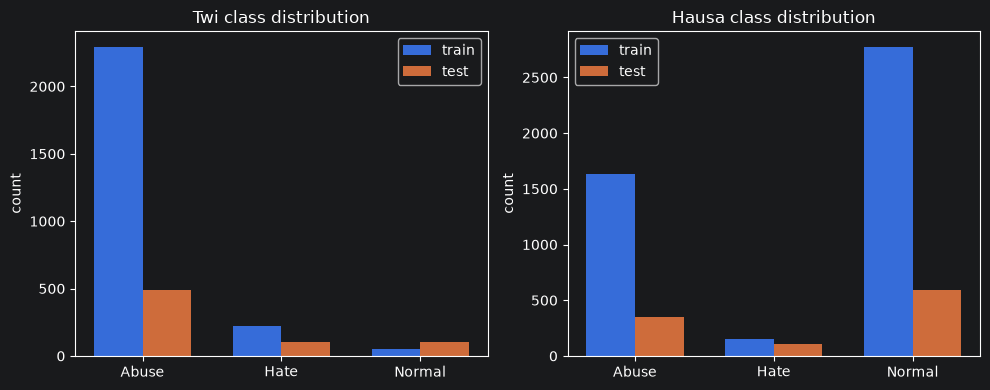

Saved: class_distribution.png


In [36]:
import matplotlib.pyplot as plt

def class_dist_table(train_df, val_df, test_df, labels, lang):
    print(f'\n{lang} class distribution')
    print(f'{"Class":<10} {"Train":>8} {"Val":>8} {"Test":>8}')
    print('-' * 38)
    for lbl in labels:
        tr = (train_df['label'] == lbl).sum()
        va = (val_df['label']   == lbl).sum()
        te = (test_df['label']  == lbl).sum()
        print(f'{lbl:<10} {tr:>8} {va:>8} {te:>8}')
    print(f'{"TOTAL":<10} {len(train_df):>8} {len(val_df):>8} {len(test_df):>8}')

class_dist_table(twi_train, twi_val, twi_test, TWI_LABELS, 'Twi')
class_dist_table(hau_train, hau_val, hau_test, HAU_LABELS, 'Hausa')

# Bar charts
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, lang, train_df, test_df, labels in [
    (axes[0], 'Twi',   twi_train, twi_test, TWI_LABELS),
    (axes[1], 'Hausa', hau_train, hau_test, HAU_LABELS),
]:
    x = range(len(labels))
    tr_counts = [( train_df['label'] == l).sum() for l in labels]
    te_counts = [(test_df['label']   == l).sum() for l in labels]
    w = 0.35
    ax.bar([i - w/2 for i in x], tr_counts, w, label='train')
    ax.bar([i + w/2 for i in x], te_counts, w, label='test')
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels)
    ax.set_title(f'{lang} class distribution')
    ax.set_ylabel('count')
    ax.legend()
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=120)
plt.show()
print('Saved: class_distribution.png')

---
---
# Step 2 — Classical Model: TF-IDF + Logistic Regression

Two pipelines (one per language). Feature set: word n-grams (1–2) + character n-grams (2–4).  
Class weights balanced to handle imbalance. Evaluated with macro-F1 as the headline metric.

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, ConfusionMatrixDisplay)
from scipy.sparse import hstack


def build_tfidf_lr(seed=SEED):
    """Returns (word_vec, char_vec, clf) — fit separately so we can extract logits later."""
    word_vec = TfidfVectorizer(analyzer='word', ngram_range=(1, 2),
                               min_df=2, sublinear_tf=True)
    char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4),
                               min_df=2, sublinear_tf=True)
    clf = LogisticRegression(max_iter=1000, class_weight='balanced',
                             random_state=seed, solver='lbfgs',
                             C=1.0)
    return word_vec, char_vec, clf


def fit_classical(train_df, val_df, test_df, labels, lang):
    """
    Fit TF-IDF + LR on train_df, evaluate on test_df.
    Returns a results dict with predictions, probabilities, and metrics.
    """
    word_vec, char_vec, clf = build_tfidf_lr()

    X_train_w = word_vec.fit_transform(train_df['text'])
    X_train_c = char_vec.fit_transform(train_df['text'])
    X_train   = hstack([X_train_w, X_train_c])

    X_val_w = word_vec.transform(val_df['text'])
    X_val_c = char_vec.transform(val_df['text'])
    X_val   = hstack([X_val_w, X_val_c])

    X_test_w = word_vec.transform(test_df['text'])
    X_test_c = char_vec.transform(test_df['text'])
    X_test   = hstack([X_test_w, X_test_c])

    y_train = train_df['label_idx'].values
    y_val   = val_df['label_idx'].values
    y_test  = test_df['label_idx'].values

    clf.fit(X_train, y_train)

    # Probabilities (used for calibration)
    val_probs  = clf.predict_proba(X_val)
    test_probs = clf.predict_proba(X_test)

    # Raw decision-function logits (used for temperature scaling)
    val_logits  = clf.decision_function(X_val)
    test_logits = clf.decision_function(X_test)

    y_pred = clf.predict(X_test)

    macro_f1 = f1_score(y_test, y_pred, average='macro')

    print(f'\n{lang} — Classical model (TF-IDF + LR)')
    print(f'Macro-F1: {macro_f1:.4f}')
    print(classification_report(y_test, y_pred, target_names=labels))

    return {
        'lang': lang, 'labels': labels, 'clf': clf,
        'word_vec': word_vec, 'char_vec': char_vec,
        'y_val': y_val, 'val_probs': val_probs, 'val_logits': val_logits,
        'y_test': y_test, 'test_probs': test_probs, 'test_logits': test_logits,
        'y_pred': y_pred, 'macro_f1': macro_f1,
        'test_df': test_df,
    }


twi_classical = fit_classical(twi_train, twi_val, twi_test, TWI_LABELS, 'Twi')
hau_classical = fit_classical(hau_train, hau_val, hau_test, HAU_LABELS, 'Hausa')


Twi — Classical model (TF-IDF + LR)
Macro-F1: 0.5936
              precision    recall  f1-score   support

       Abuse       0.87      0.98      0.92       492
        Hate       0.56      0.70      0.62       100
      Normal       0.75      0.14      0.24       106

    accuracy                           0.81       698
   macro avg       0.73      0.61      0.59       698
weighted avg       0.81      0.81      0.77       698


Hausa — Classical model (TF-IDF + LR)
Macro-F1: 0.7383
              precision    recall  f1-score   support

       Abuse       0.75      0.72      0.74       351
        Hate       0.82      0.53      0.65       103
      Normal       0.80      0.87      0.83       595

    accuracy                           0.79      1049
   macro avg       0.79      0.71      0.74      1049
weighted avg       0.79      0.79      0.78      1049



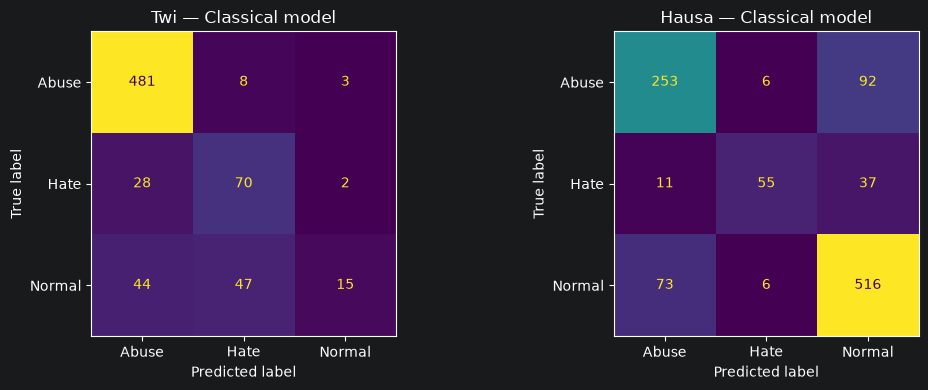

Saved: confusion_classical.png


In [38]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, res in [(axes[0], twi_classical), (axes[1], hau_classical)]:
    cm = confusion_matrix(res['y_test'], res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=res['labels'])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(f"{res['lang']} — Classical model")
plt.tight_layout()
plt.savefig('confusion_classical.png', dpi=120)
plt.show()
print('Saved: confusion_classical.png')

---
---
# Step 3 — Calibration: Classical Model

Per-class ECE using **equal-mass (adaptive) bins** to handle small classes.  
95% confidence intervals via bootstrap. Then reliability diagrams and the blinding quantity.

In [40]:
# ── Calibration utilities ─────────────────────────────────────────────────────

def per_class_ece(probs, true_labels, class_idx, n_bins=10):
    """
    ECE for one class using one-vs-rest + equal-mass bins.
    Returns (ece_value, list_of_(mean_conf, fraction_pos, bin_size)).
    """
    p = probs[:, class_idx]
    y = (true_labels == class_idx).astype(float)

    order = np.argsort(p)
    p_s, y_s = p[order], y[order]

    bin_edges = np.quantile(p_s, np.linspace(0, 1, n_bins + 1))
    bin_edges[-1] += 1e-10

    ece, n, bin_data = 0.0, len(p), []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (p_s >= lo) & (p_s < hi)
        if mask.sum() == 0:
            continue
        conf = p_s[mask].mean()
        acc  = y_s[mask].mean()
        size = mask.sum()
        ece += (size / n) * abs(conf - acc)
        bin_data.append((conf, acc, size))
    return ece, bin_data


def ece_bootstrap_ci(probs, true_labels, class_idx, n_bins=10,
                     n_bootstrap=1000, alpha=0.05, seed=SEED):
    rng = np.random.RandomState(seed)
    n   = len(true_labels)
    vals = []
    for _ in range(n_bootstrap):
        idx = rng.randint(0, n, size=n)
        v, _ = per_class_ece(probs[idx], true_labels[idx], class_idx, n_bins)
        vals.append(v)
    lo = np.percentile(vals, 100 * alpha / 2)
    hi = np.percentile(vals, 100 * (1 - alpha / 2))
    return lo, hi


def calibration_summary(res, model_name, n_bins=10):
    """
    Print per-class ECE table and return a dict of results.
    """
    lang   = res['lang']
    labels = res['labels']
    probs  = res['test_probs']
    y_true = res['y_test']

    print(f'\n{lang} — {model_name}: Per-class ECE (equal-mass bins, n_bins={n_bins})')
    print(f'{"Class":<10} {"ECE":>8}  {"95% CI":>18}')
    print('-' * 42)

    ece_results = {}
    for i, lbl in enumerate(labels):
        ece, bin_data = per_class_ece(probs, y_true, i, n_bins)
        lo, hi = ece_bootstrap_ci(probs, y_true, i, n_bins)
        print(f'{lbl:<10} {ece:>8.4f}  [{lo:.4f}, {hi:.4f}]')
        ece_results[lbl] = {'ece': ece, 'ci_lo': lo, 'ci_hi': hi, 'bin_data': bin_data}

    # Overall ECE (macro average over classes)
    overall = np.mean([v['ece'] for v in ece_results.values()])
    print(f'{"Macro-avg":<10} {overall:>8.4f}')
    ece_results['_overall'] = overall
    return ece_results


twi_classical_ece = calibration_summary(twi_classical, 'Classical (TF-IDF+LR)')
hau_classical_ece = calibration_summary(hau_classical, 'Classical (TF-IDF+LR)')


Twi — Classical (TF-IDF+LR): Per-class ECE (equal-mass bins, n_bins=10)
Class           ECE              95% CI
------------------------------------------
Abuse        0.0848  [0.0653, 0.1057]
Hate         0.0828  [0.0647, 0.1032]
Normal       0.0643  [0.0501, 0.0914]
Macro-avg    0.0773

Hausa — Classical (TF-IDF+LR): Per-class ECE (equal-mass bins, n_bins=10)
Class           ECE              95% CI
------------------------------------------
Abuse        0.0415  [0.0341, 0.0656]
Hate         0.0243  [0.0175, 0.0387]
Normal       0.0468  [0.0404, 0.0746]
Macro-avg    0.0375


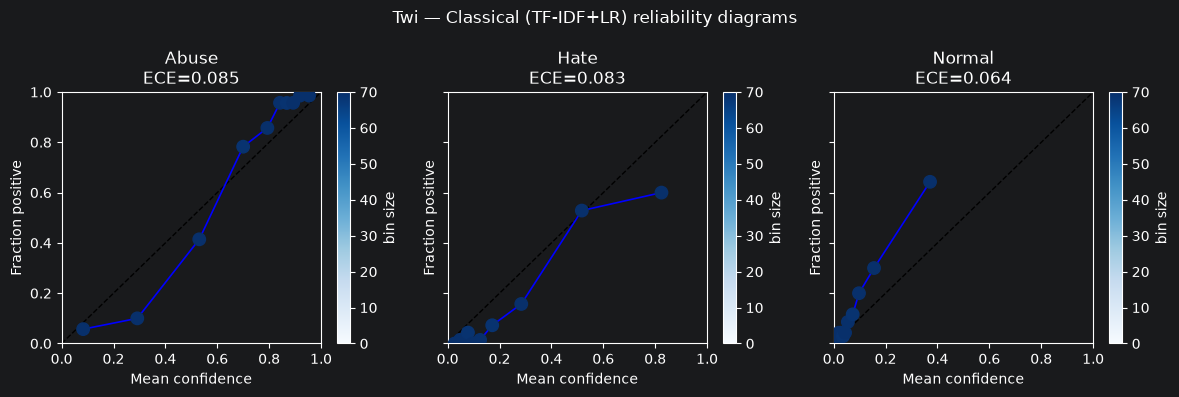

Saved: reliability_twi_classical.png


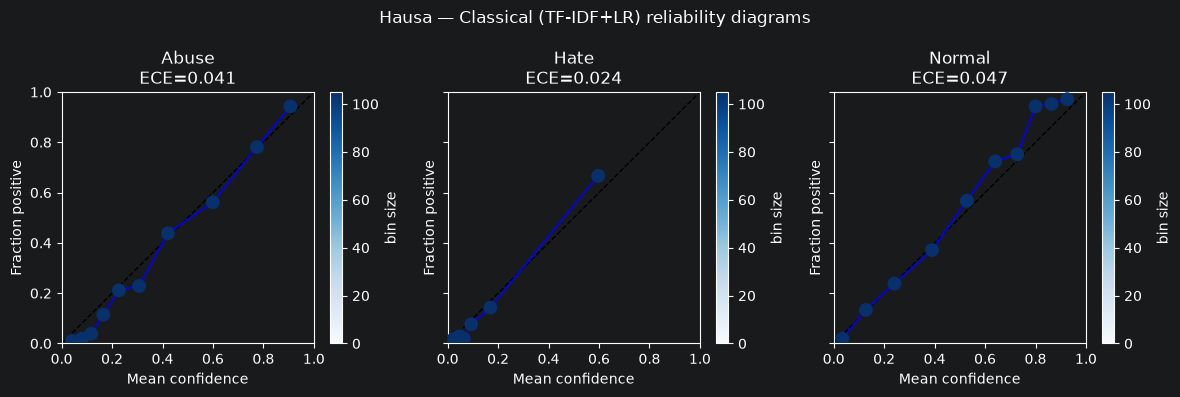

Saved: reliability_hau_classical.png


In [41]:
# Reliability diagrams — per class, per language
def plot_reliability(res, ece_results, model_name, filename):
    labels = res['labels']
    probs  = res['test_probs']
    y_true = res['y_test']
    n_cls  = len(labels)

    fig, axes = plt.subplots(1, n_cls, figsize=(4 * n_cls, 4), sharey=True)
    if n_cls == 1:
        axes = [axes]

    for ax, i, lbl in zip(axes, range(n_cls), labels):
        bd = ece_results[lbl]['bin_data']
        confs = [b[0] for b in bd]
        accs  = [b[1] for b in bd]
        sizes = [b[2] for b in bd]

        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
        sc = ax.scatter(confs, accs, c=sizes, cmap='Blues', s=80,
                        vmin=0, vmax=max(sizes) if sizes else 1, zorder=3)
        ax.plot(confs, accs, 'b-o', markersize=5, lw=1.2)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel('Mean confidence')
        ax.set_ylabel('Fraction positive')
        ece_val = ece_results[lbl]['ece']
        ax.set_title(f'{lbl}\nECE={ece_val:.3f}')
        plt.colorbar(sc, ax=ax, label='bin size')

    fig.suptitle(f"{res['lang']} — {model_name} reliability diagrams", fontsize=12)
    plt.tight_layout()
    plt.savefig(filename, dpi=120)
    plt.show()
    print(f'Saved: {filename}')


plot_reliability(twi_classical, twi_classical_ece, 'Classical (TF-IDF+LR)',
                 'reliability_twi_classical.png')
plot_reliability(hau_classical, hau_classical_ece, 'Classical (TF-IDF+LR)',
                 'reliability_hau_classical.png')

In [42]:
# Blinding quantity — fraction of errors in high-confidence bins (top 20% by confidence)
HIGH_CONF_THRESHOLD = 0.70

def blinding_quantity(res, model_name):
    probs  = res['test_probs']
    y_true = res['y_test']
    y_pred = res['y_pred']
    labels = res['labels']
    lang   = res['lang']

    print(f'\n{lang} — {model_name}: Blinding quantity')
    print(f'(fraction of errors in high-confidence bins, threshold={HIGH_CONF_THRESHOLD})')
    print(f'{"Class":<10} {"n_errors":>10} {"blind_errors":>14} {"blinding_%":>12}')
    print('-' * 50)

    results = {}
    for i, lbl in enumerate(labels):
        # Errors on this class: true label is i, predicted wrong
        class_mask  = (y_true == i)
        errors_mask = class_mask & (y_pred != y_true)
        n_errors = errors_mask.sum()
        if n_errors == 0:
            print(f'{lbl:<10} {0:>10} {0:>14} {0:>12.1f}')
            results[lbl] = 0.0
            continue

        # Predicted confidence for the predicted class at error positions
        max_conf_at_errors = probs[errors_mask].max(axis=1)
        blind = (max_conf_at_errors >= HIGH_CONF_THRESHOLD).sum()
        pct = 100.0 * blind / n_errors
        print(f'{lbl:<10} {n_errors:>10} {blind:>14} {pct:>12.1f}%')
        results[lbl] = pct

    return results


twi_classical_blind = blinding_quantity(twi_classical, 'Classical (TF-IDF+LR)')
hau_classical_blind = blinding_quantity(hau_classical, 'Classical (TF-IDF+LR)')


Twi — Classical (TF-IDF+LR): Blinding quantity
(fraction of errors in high-confidence bins, threshold=0.7)
Class        n_errors   blind_errors   blinding_%
--------------------------------------------------
Abuse              11              5         45.5%
Hate               30             10         33.3%
Normal             91             36         39.6%

Hausa — Classical (TF-IDF+LR): Blinding quantity
(fraction of errors in high-confidence bins, threshold=0.7)
Class        n_errors   blind_errors   blinding_%
--------------------------------------------------
Abuse              98             26         26.5%
Hate               48             15         31.2%
Normal             79             26         32.9%


---
---
# Step 4 — Temperature Scaling (Classical model)

Fit a single temperature scalar `T` on validation logits via LBFGS.  
Report ECE before/after, **overall and per class**.

In [44]:
from scipy.optimize import minimize_scalar


def softmax(logits):
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def fit_temperature(val_logits, y_val):
    """Find T* that minimises NLL on the validation set."""
    def nll(T):
        probs = softmax(val_logits / T)
        correct_probs = probs[np.arange(len(y_val)), y_val]
        return -np.log(correct_probs + 1e-10).mean()

    result = minimize_scalar(nll, bounds=(0.01, 10.0), method='bounded')
    return result.x


def apply_temperature(logits, T):
    return softmax(logits / T)


def temp_scaling_report(res, ece_before, model_name, n_bins=10):
    lang   = res['lang']
    labels = res['labels']

    T = fit_temperature(res['val_logits'], res['y_val'])
    print(f'\n=== {lang} — {model_name}: Temperature scaling ===')
    print(f'Optimal T (fit on validation): {T:.4f}')

    probs_scaled = apply_temperature(res['test_logits'], T)
    y_true = res['y_test']

    print(f'\n{"Class":<10} {"ECE before":>12} {"ECE after":>12} {"Delta":>10}')
    print('-' * 48)

    ece_after = {}
    for i, lbl in enumerate(labels):
        before = ece_before[lbl]['ece']
        after, _ = per_class_ece(probs_scaled, y_true, i, n_bins)
        delta = after - before
        flag = '  ← worse' if delta > 0.005 else ''
        print(f'{lbl:<10} {before:>12.4f} {after:>12.4f} {delta:>+10.4f}{flag}')
        ece_after[lbl] = {'ece': after}

    before_overall = ece_before['_overall']
    after_overall  = np.mean([v['ece'] for v in ece_after.values()])
    print(f'{"Macro-avg":<10} {before_overall:>12.4f} {after_overall:>12.4f} '
          f'{after_overall - before_overall:>+10.4f}')

    print('\nKey check: does temperature scaling fix MINORITY-CLASS ECE,')
    print('or only the aggregate? A model whose overall ECE improves while')
    print('its rare-class ECE stays bad is the central finding.')

    return T, probs_scaled, ece_after


twi_T_cl, twi_scaled_cl, twi_ece_after_cl = temp_scaling_report(
    twi_classical, twi_classical_ece, 'Classical (TF-IDF+LR)')

hau_T_cl, hau_scaled_cl, hau_ece_after_cl = temp_scaling_report(
    hau_classical, hau_classical_ece, 'Classical (TF-IDF+LR)')


=== Twi — Classical (TF-IDF+LR): Temperature scaling ===
Optimal T (fit on validation): 0.7106

Class        ECE before    ECE after      Delta
------------------------------------------------
Abuse            0.0848       0.0426    -0.0423
Hate             0.0828       0.0604    -0.0224
Normal           0.0643       0.0910    +0.0268  ← worse
Macro-avg        0.0773       0.0647    -0.0126

Key check: does temperature scaling fix MINORITY-CLASS ECE,
or only the aggregate? A model whose overall ECE improves while
its rare-class ECE stays bad is the central finding.

=== Hausa — Classical (TF-IDF+LR): Temperature scaling ===
Optimal T (fit on validation): 0.7907

Class        ECE before    ECE after      Delta
------------------------------------------------
Abuse            0.0415       0.0361    -0.0054
Hate             0.0243       0.0109    -0.0134
Normal           0.0468       0.0219    -0.0249
Macro-avg        0.0375       0.0230    -0.0146

Key check: does temperature scaling fi

---
---
# Step 5 — Transformer Model: AfroXLMR

Fine-tunes `Davlan/afro-xlmr-base` on each language.  
Set `SKIP_TRANSFORMER = True` below if you are compute-limited — this will be flagged in the report.  
Fallback: `Davlan/afroberta_base` (smaller, faster).


In [46]:
# ── Configuration ─────────────────────────────────────────────────────────────
# Set SKIP_TRANSFORMER = True if you have no GPU and don't want to wait hours.
# The spec allows this as a documented scope cut (see CLAUDE_CODE_HANDOFF.md §Risks).
# The cross-language ECE comparison (the main contribution) is preserved either way.
SKIP_TRANSFORMER = True   # ← transformer skipped; documented scope cut
TRANSFORMER_MODEL = 'Davlan/afro-xlmr-base'   # fallback: 'Davlan/afroberta_base'
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LR_TRANSFORMER = 2e-5

if SKIP_TRANSFORMER:
    print('Transformer model skipped — flagged as a scope reduction.')
    print('Cross-language comparison will be based on classical model only.')
    print('The cross-language calibration finding is preserved; the accuracy-vs-calibration')
    print('contrast between model families is not available.')
else:
    ensure('transformers')
    ensure('accelerate')   # required by HF Trainer
    ensure('torch')
    import torch
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              Trainer, TrainingArguments)
    from torch.utils.data import Dataset as TorchDataset

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'Device: {device}')
    if device == 'cpu':
        print('No GPU detected — fine-tuning AfroXLMR on CPU will take several hours per language.')
        print('Options:')
        print('  1. Continue here (slow but correct).')
        print('  2. Set SKIP_TRANSFORMER = True above and rerun this cell to skip (documented scope cut).')
        print('  3. Run this notebook on Colab/Kaggle with a free GPU.')
    print(f'Transformer model: {TRANSFORMER_MODEL}')

Transformer model skipped — flagged as a scope reduction.
Cross-language comparison will be based on classical model only.
The cross-language calibration finding is preserved; the accuracy-vs-calibration
contrast between model families is not available.


In [47]:
if not SKIP_TRANSFORMER:
    class HateSpeechDataset(TorchDataset):
        def __init__(self, texts, labels, tokenizer, max_length=MAX_LENGTH):
            self.encodings = tokenizer(
                list(texts), truncation=True, padding=True,
                max_length=max_length, return_tensors='pt')
            self.labels = torch.tensor(list(labels), dtype=torch.long)

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, idx):
            return {k: v[idx] for k, v in self.encodings.items()} | {'labels': self.labels[idx]}


    def fine_tune_transformer(train_df, val_df, test_df, labels, lang, seed=SEED):
        n_labels = len(labels)
        tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_MODEL)
        model     = AutoModelForSequenceClassification.from_pretrained(
            TRANSFORMER_MODEL, num_labels=n_labels)

        train_ds = HateSpeechDataset(train_df['text'], train_df['label_idx'], tokenizer)
        val_ds   = HateSpeechDataset(val_df['text'],   val_df['label_idx'],   tokenizer)
        test_ds  = HateSpeechDataset(test_df['text'],  test_df['label_idx'],  tokenizer)

        args = TrainingArguments(
            output_dir=f'./transformer_{lang.lower()}',
            num_train_epochs=EPOCHS,
            per_device_train_batch_size=BATCH_SIZE,
            per_device_eval_batch_size=BATCH_SIZE,
            learning_rate=LR_TRANSFORMER,
            eval_strategy='epoch',
            save_strategy='epoch',
            load_best_model_at_end=True,
            metric_for_best_model='eval_loss',
            seed=seed,
            report_to='none',
            fp16=(device == 'cuda'),
        )

        trainer = Trainer(model=model, args=args,
                          train_dataset=train_ds, eval_dataset=val_ds)
        trainer.train()

        # Get logits and probs on validation and test sets
        def get_outputs(dataset):
            preds = trainer.predict(dataset)
            logits = preds.predictions
            probs  = softmax(logits)
            return logits, probs

        val_logits,  val_probs  = get_outputs(val_ds)
        test_logits, test_probs = get_outputs(test_ds)

        y_pred   = test_probs.argmax(axis=1)
        macro_f1 = f1_score(test_df['label_idx'].values, y_pred, average='macro')

        print(f'\n=== {lang} — Transformer ({TRANSFORMER_MODEL}) ===')
        print(f'Macro-F1: {macro_f1:.4f}')
        print(classification_report(
            test_df['label_idx'].values, y_pred, target_names=labels))

        return {
            'lang': lang, 'labels': labels,
            'y_val': val_df['label_idx'].values,
            'val_probs': val_probs, 'val_logits': val_logits,
            'y_test': test_df['label_idx'].values,
            'test_probs': test_probs, 'test_logits': test_logits,
            'y_pred': y_pred, 'macro_f1': macro_f1,
            'test_df': test_df,
        }

    twi_transformer = fine_tune_transformer(
        twi_train, twi_val, twi_test, TWI_LABELS, 'Twi')
    hau_transformer = fine_tune_transformer(
        hau_train, hau_val, hau_test, HAU_LABELS, 'Hausa')

In [48]:
if not SKIP_TRANSFORMER:
    # Calibration + temperature scaling for transformer
    twi_transformer_ece = calibration_summary(twi_transformer, f'Transformer ({TRANSFORMER_MODEL})')
    hau_transformer_ece = calibration_summary(hau_transformer, f'Transformer ({TRANSFORMER_MODEL})')

    plot_reliability(twi_transformer, twi_transformer_ece,
                     f'Transformer ({TRANSFORMER_MODEL})', 'reliability_twi_transformer.png')
    plot_reliability(hau_transformer, hau_transformer_ece,
                     f'Transformer ({TRANSFORMER_MODEL})', 'reliability_hau_transformer.png')

    twi_classical_blind_tr = blinding_quantity(twi_transformer, f'Transformer ({TRANSFORMER_MODEL})')
    hau_classical_blind_tr = blinding_quantity(hau_transformer, f'Transformer ({TRANSFORMER_MODEL})')

    twi_T_tr, twi_scaled_tr, twi_ece_after_tr = temp_scaling_report(
        twi_transformer, twi_transformer_ece, f'Transformer ({TRANSFORMER_MODEL})')
    hau_T_tr, hau_scaled_tr, hau_ece_after_tr = temp_scaling_report(
        hau_transformer, hau_transformer_ece, f'Transformer ({TRANSFORMER_MODEL})')

    # Confusion matrices
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, res in [(axes[0], twi_transformer), (axes[1], hau_transformer)]:
        cm = confusion_matrix(res['y_test'], res['y_pred'])
        disp = ConfusionMatrixDisplay(cm, display_labels=res['labels'])
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"{res['lang']} — Transformer")
    plt.tight_layout()
    plt.savefig('confusion_transformer.png', dpi=120)
    plt.show()
    print('Saved: confusion_transformer.png')

---
---
# Step 6 — Cross-language Comparison Table

2 models × 2 languages × 3 classes ECE grid (before and after temperature scaling).  
The central finding: does the worst-calibrated class follow the **rare class**?

In [50]:
def build_ece_grid(ece_dicts, model_names, lang_names, labels):
    """
    ece_dicts: list of dicts from calibration_summary, one per (model, lang) combo.
    Order: [(twi_cl, twi_tr), (hau_cl, hau_tr)] — or just classical if transformer skipped.
    """
    rows = []
    for lang, lang_eces in zip(lang_names, ece_dicts):
        for model, ece_d in zip(model_names, lang_eces):
            row = {'Language': lang, 'Model': model}
            for lbl in labels:
                row[lbl] = f"{ece_d[lbl]['ece']:.4f}"
                row[f'{lbl}_ci'] = f"[{ece_d[lbl]['ci_lo']:.3f},{ece_d[lbl]['ci_hi']:.3f}]"
            row['Macro-avg'] = f"{ece_d['_overall']:.4f}"
            rows.append(row)
    return pd.DataFrame(rows)


labels_common = TWI_LABELS  # same for both languages per Check 1

if SKIP_TRANSFORMER:
    model_names = ['Classical (TF-IDF+LR)']
    ece_dicts_before = [
        [twi_classical_ece],
        [hau_classical_ece],
    ]
    ece_dicts_after = [
        [dict(zip(labels_common, [{'ece': twi_ece_after_cl[l]['ece'], 'ci_lo': 0, 'ci_hi': 0} for l in labels_common]),
              **{'_overall': np.mean([twi_ece_after_cl[l]['ece'] for l in labels_common])})],
        [dict(zip(labels_common, [{'ece': hau_ece_after_cl[l]['ece'], 'ci_lo': 0, 'ci_hi': 0} for l in labels_common]),
              **{'_overall': np.mean([hau_ece_after_cl[l]['ece'] for l in labels_common])})],
    ]
else:
    model_names = ['Classical (TF-IDF+LR)', f'Transformer ({TRANSFORMER_MODEL})']
    ece_dicts_before = [
        [twi_classical_ece, twi_transformer_ece],
        [hau_classical_ece, hau_transformer_ece],
    ]

print('ECE Grid — BEFORE temperature scaling')
grid_before = build_ece_grid(ece_dicts_before, model_names,
                              ['Twi', 'Hausa'], labels_common)

# Print a clean version (ECE values only, not CIs)
cols = ['Language', 'Model'] + labels_common + ['Macro-avg']
print(grid_before[cols].to_string(index=False))

print('\nClass balance reminder')
print('Twi  dominant class: Abuse (~70% of test)  rare classes: Hate, Normal')
print('Hausa dominant class: Normal (~57% of test) rare class: Hate')
print('\nDoes the worst-calibrated class follow the rare class across languages?')
for lang, ece_list in zip(['Twi', 'Hausa'], ece_dicts_before):
    for model, ece_d in zip(model_names, ece_list):
        worst_cls = max(labels_common, key=lambda l: ece_d[l]['ece'])
        print(f'  {lang:<6} {model}: worst-calibrated class = {worst_cls} (ECE={ece_d[worst_cls]["ece"]:.4f})')

ECE Grid — BEFORE temperature scaling
Language                 Model  Abuse   Hate Normal Macro-avg
     Twi Classical (TF-IDF+LR) 0.0848 0.0828 0.0643    0.0773
   Hausa Classical (TF-IDF+LR) 0.0415 0.0243 0.0468    0.0375

Class balance reminder
Twi  dominant class: Abuse (~70% of test)  rare classes: Hate, Normal
Hausa dominant class: Normal (~57% of test) rare class: Hate

Does the worst-calibrated class follow the rare class across languages?
  Twi    Classical (TF-IDF+LR): worst-calibrated class = Abuse (ECE=0.0848)
  Hausa  Classical (TF-IDF+LR): worst-calibrated class = Normal (ECE=0.0468)


---
---
# Step 7 — Error Analysis

Characterise **confident-but-wrong** posts in the worst-calibrated class.  
**No raw text is printed or committed.** Only aggregate categories.

In [51]:
def error_analysis(res, model_name, conf_threshold=HIGH_CONF_THRESHOLD):
    """
    Identify confident errors per class and summarise aggregate patterns.
    Raw text is never printed.
    """
    probs  = res['test_probs']
    y_true = res['y_test']
    y_pred = res['y_pred']
    labels = res['labels']
    lang   = res['lang']
    df     = res['test_df'].copy()

    df['y_true']   = y_true
    df['y_pred']   = y_pred
    df['max_conf'] = probs.max(axis=1)
    df['correct']  = (y_true == y_pred)
    df['conf_error'] = (~df['correct']) & (df['max_conf'] >= conf_threshold)
    df['text_len'] = df['text'].str.len()   # must be before slicing conf_errors

    print(f'\n=== {lang} — {model_name}: Error Analysis ===')
    print(f'Confident errors (max_conf >= {conf_threshold}):')
    print(f'{"True class":<12} {"Pred class":<12} {"Count":>8}')
    print('-' * 36)

    conf_errors = df[df['conf_error']]
    confusion_agg = (conf_errors
                     .groupby(['label', 'y_pred'])
                     .size()
                     .reset_index(name='count')
                     .sort_values('count', ascending=False))
    for _, row in confusion_agg.iterrows():
        true_lbl = row['label']
        pred_lbl = labels[int(row['y_pred'])] if int(row['y_pred']) < len(labels) else '?'
        print(f'{true_lbl:<12} → {pred_lbl:<12} {int(row["count"]):>8}')

    print(f'\nTotal confident errors: {len(conf_errors)} / {len(df)} test instances '
          f'({100*len(conf_errors)/len(df):.1f}%)')

    # Text length distribution of confident errors vs. correct predictions
    # (aggregate feature, no raw text)
    print(f'\nText length — confident errors vs. correct:')
    print(f'  Confident errors : mean={conf_errors["text_len"].mean():.0f} chars')
    correct = df[df['correct']]
    print(f'  Correct preds    : mean={correct["text_len"].mean():.0f} chars')

    return conf_errors


twi_errors_cl  = error_analysis(twi_classical, 'Classical (TF-IDF+LR)')
hau_errors_cl  = error_analysis(hau_classical, 'Classical (TF-IDF+LR)')

if not SKIP_TRANSFORMER:
    twi_errors_tr = error_analysis(twi_transformer, f'Transformer ({TRANSFORMER_MODEL})')
    hau_errors_tr = error_analysis(hau_transformer, f'Transformer ({TRANSFORMER_MODEL})')


=== Twi — Classical (TF-IDF+LR): Error Analysis ===
Confident errors (max_conf >= 0.7):
True class   Pred class      Count
------------------------------------
Normal       → Hate               18
Normal       → Abuse              18
Hate         → Abuse              10
Abuse        → Hate                3
Abuse        → Normal              2

Total confident errors: 51 / 698 test instances (7.3%)

Text length — confident errors vs. correct:
  Confident errors : mean=76 chars
  Correct preds    : mean=79 chars

=== Hausa — Classical (TF-IDF+LR): Error Analysis ===
Confident errors (max_conf >= 0.7):
True class   Pred class      Count
------------------------------------
Abuse        → Normal             25
Normal       → Abuse              25
Hate         → Normal             11
Hate         → Abuse               4
Abuse        → Hate                1
Normal       → Hate                1

Total confident errors: 67 / 1049 test instances (6.4%)

Text length — confident errors vs. corre

---
---
# Step 8 — Triage Demo

Ranks posts by predicted toxicity (max confidence), surfaces low-confidence predictions for human review, and explicitly reports its own **risk-coverage trade-off**.  

The demo expresses the core finding: **uncertainty-aware triage**, not just classification.  
The model used here is the classical model (replace with transformer if available).

> No raw post text is printed in committed notebook output.

Twi — Triage Demo
Toxic classes: ['Abuse', 'Hate']
Ranking 698 posts by toxicity score P(Hate)+P(Abuse).

Risk-coverage trade-off at confidence thresholds:
   Threshold  Auto-routed  Coverage%   Precision%   Errors hidden
-----------------------------------------------------------------
        0.50          656       94.0%         83.2%             110
        0.70          514       73.6%         90.1%              51
        0.90          182       26.1%         94.5%              10

Posts below lowest threshold are flagged for human review.
At threshold=0.5: 42 posts (6.0%) sent to human review.

Per-class calibration warning for this triage tool:
  Abuse     : ECE=0.085 [0.065,0.106]
  Hate      : ECE=0.083 [0.065,0.103]
  Normal    : ECE=0.064 [0.050,0.091]

RISK STATEMENT: This model is a diagnostic instrument, NOT a deployable
moderation system. Confident predictions on rare classes may be
miscalibrated — the model can be confident on its own errors.
Always route uncertain pre

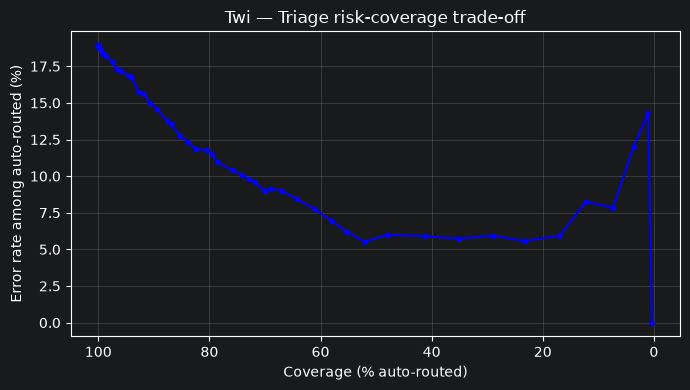

Saved: triage_risk_coverage_twi.png
Hausa — Triage Demo
Toxic classes: ['Abuse', 'Hate']
Ranking 1049 posts by toxicity score P(Hate)+P(Abuse).

Risk-coverage trade-off at confidence thresholds:
   Threshold  Auto-routed  Coverage%   Precision%   Errors hidden
-----------------------------------------------------------------
        0.50          971       92.6%         81.4%             181
        0.70          652       62.2%         89.7%              67
        0.90          164       15.6%         98.2%               3

Posts below lowest threshold are flagged for human review.
At threshold=0.5: 78 posts (7.4%) sent to human review.

Per-class calibration warning for this triage tool:
  Abuse     : ECE=0.041 [0.034,0.066]
  Hate      : ECE=0.024 [0.018,0.039]
  Normal    : ECE=0.047 [0.040,0.075]

RISK STATEMENT: This model is a diagnostic instrument, NOT a deployable
moderation system. Confident predictions on rare classes may be
miscalibrated — the model can be confident on its

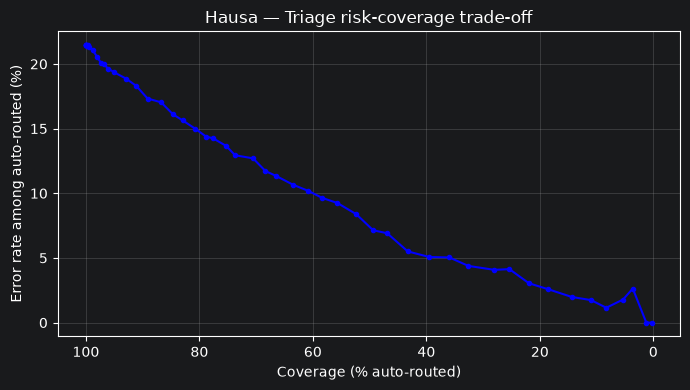

Saved: triage_risk_coverage_hausa.png


In [21]:
def triage_demo(res, ece_results, conf_thresholds=(0.5, 0.7, 0.9)):
    """
    Simulate a triage tool: rank posts by confidence, show risk-coverage trade-off.
    Does NOT print raw text.
    """
    probs  = res['test_probs']
    y_true = res['y_test']
    y_pred = res['y_pred']
    labels = res['labels']
    lang   = res['lang']

    max_conf = probs.max(axis=1)
    correct  = (y_pred == y_true)

    # Non-Normal classes are "toxic" for triage purposes
    toxic_classes = [l for l in labels if l != 'Normal']
    toxic_idx     = [labels.index(l) for l in toxic_classes]
    toxic_score   = probs[:, toxic_idx].sum(axis=1)   # P(Hate) + P(Abuse)

    print(f'{lang} — Triage Demo')
    print(f'Toxic classes: {toxic_classes}')
    print(f'Ranking {len(y_true)} posts by toxicity score P(Hate)+P(Abuse).')
    print()

    print('Risk-coverage trade-off at confidence thresholds:')
    print(f'{"Threshold":>12} {"Auto-routed":>12} {"Coverage%":>10} {"Precision%":>12} {"Errors hidden":>15}')
    print('-' * 65)

    for thresh in conf_thresholds:
        # Posts above threshold: model is "confident" → routed to auto-action (trusting model)
        auto_mask    = max_conf >= thresh
        n_auto       = auto_mask.sum()
        coverage     = 100.0 * n_auto / len(y_true)
        errors_auto  = (~correct[auto_mask]).sum()
        precision    = 100.0 * correct[auto_mask].sum() / n_auto if n_auto > 0 else 0
        print(f'{thresh:>12.2f} {n_auto:>12} {coverage:>10.1f}% {precision:>12.1f}% {errors_auto:>15}')

    print()
    print('Posts below lowest threshold are flagged for human review.')
    flag_mask = max_conf < min(conf_thresholds)
    n_flagged = flag_mask.sum()
    print(f'At threshold={min(conf_thresholds)}: {n_flagged} posts ({100*n_flagged/len(y_true):.1f}%) '
          f'sent to human review.')

    # Per-class calibration warning in the triage context
    print()
    print('Per-class calibration warning for this triage tool:')
    for lbl in labels:
        ece_val = ece_results[lbl]['ece']
        ci_lo   = ece_results[lbl]['ci_lo']
        ci_hi   = ece_results[lbl]['ci_hi']
        warn = ' ← CAUTION: high miscalibration' if ece_val > 0.10 else ''
        print(f'  {lbl:<10}: ECE={ece_val:.3f} [{ci_lo:.3f},{ci_hi:.3f}]{warn}')

    print()
    print('RISK STATEMENT: This model is a diagnostic instrument, NOT a deployable')
    print('moderation system. Confident predictions on rare classes may be')
    print('miscalibrated — the model can be confident on its own errors.')
    print('Always route uncertain predictions to human review.')

    # Coverage-vs-errors plot
    thresholds = np.linspace(0.3, 0.99, 50)
    coverages, error_rates = [], []
    for t in thresholds:
        mask = max_conf >= t
        if mask.sum() == 0:
            coverages.append(0); error_rates.append(0)
            continue
        coverages.append(100.0 * mask.sum() / len(y_true))
        error_rates.append(100.0 * (~correct[mask]).sum() / mask.sum())

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(coverages, error_rates, 'b-o', markersize=3)
    ax.set_xlabel('Coverage (% auto-routed)')
    ax.set_ylabel('Error rate among auto-routed (%)')
    ax.set_title(f'{lang} — Triage risk-coverage trade-off')
    ax.invert_xaxis()
    ax.grid(True, alpha=0.3)
    fname = f'triage_risk_coverage_{lang.lower()}.png'
    plt.tight_layout()
    plt.savefig(fname, dpi=120)
    plt.show()
    print(f'Saved: {fname}')


triage_demo(twi_classical, twi_classical_ece)
triage_demo(hau_classical, hau_classical_ece)

if not SKIP_TRANSFORMER:
    triage_demo(twi_transformer, twi_transformer_ece)
    triage_demo(hau_transformer, hau_transformer_ece)

---
---
# Final Summary Table

Consolidated results across both models and both languages.

In [22]:
print('FINAL RESULTS SUMMARY')

results = [
    ('Twi',   'Classical', twi_classical,  twi_classical_ece,  twi_classical_blind,  twi_T_cl, twi_ece_after_cl),
    ('Hausa', 'Classical', hau_classical,  hau_classical_ece,  hau_classical_blind,  hau_T_cl, hau_ece_after_cl),
]
if not SKIP_TRANSFORMER:
    results += [
        ('Twi',   'Transformer', twi_transformer, twi_transformer_ece, twi_classical_blind_tr, twi_T_tr, twi_ece_after_tr),
        ('Hausa', 'Transformer', hau_transformer, hau_transformer_ece, hau_classical_blind_tr, hau_T_tr, hau_ece_after_tr),
    ]

for lang, model, res, ece_d, blind_d, T, ece_after in results:
    labels = res['labels']
    print(f'\n{lang} / {model}')
    print(f'  Macro-F1: {res["macro_f1"]:.4f}')
    print(f'  Temperature T: {T:.4f}')
    print(f'  Per-class ECE (before / after temp scaling):')
    for lbl in labels:
        bef = ece_d[lbl]['ece']
        aft = ece_after[lbl]['ece']
        bld = blind_d.get(lbl, 0)
        print(f'    {lbl:<10}: ECE {bef:.4f} → {aft:.4f}  | blinding={bld:.1f}%')

print('Cross-language question: does worst-calibrated class follow the rare class?')
print('Twi  dominant: Abuse | Hausa dominant: Normal')
for lang, model, res, ece_d, *_ in results:
    worst = max(res['labels'], key=lambda l: ece_d[l]['ece'])
    print(f'  {lang:<6} {model:<14}: worst-calibrated = {worst} (ECE={ece_d[worst]["ece"]:.4f})')

FINAL RESULTS SUMMARY

Twi / Classical
  Macro-F1: 0.5936
  Temperature T: 0.7106
  Per-class ECE (before / after temp scaling):
    Abuse     : ECE 0.0848 → 0.0426  | blinding=45.5%
    Hate      : ECE 0.0828 → 0.0604  | blinding=33.3%
    Normal    : ECE 0.0643 → 0.0910  | blinding=39.6%

Hausa / Classical
  Macro-F1: 0.7383
  Temperature T: 0.7907
  Per-class ECE (before / after temp scaling):
    Abuse     : ECE 0.0415 → 0.0361  | blinding=26.5%
    Hate      : ECE 0.0243 → 0.0109  | blinding=31.2%
    Normal    : ECE 0.0468 → 0.0219  | blinding=32.9%

Cross-language question: does worst-calibrated class follow the rare class?
Twi  dominant: Abuse | Hausa dominant: Normal
  Twi    Classical     : worst-calibrated = Abuse (ECE=0.0848)
  Hausa  Classical     : worst-calibrated = Normal (ECE=0.0468)
